# Práctico 3.3 | Análisis de la microbiota a nivel filo y familia
**Bioinformática en el Diagnóstico Molecular**

## Contexto experimental

La microbiota intestinal desempeña un papel fundamental en la regulación del sistema inmunitario, el metabolismo y la salud del hospedero. Factores ambientales y farmacológicos, como la exposición a microplásticos y la administración de antibióticos, pueden modificar su composición y diversidad.

En este práctico se propone un modelo experimental murino para evaluar el efecto de los microplásticos y los antibióticos sobre la microbiota intestinal. El diseño contempla 24 muestras distribuidas en cuatro grupos experimentales:

| Grupo experimental | Número de muestras |
|---|---:|
| Control | 6 |
| Antibióticos | 6 |
| Microplásticos | 6 |
| Microplásticos + Antibióticos | 6 |

Para caracterizar la microbiota intestinal, utilizaremos los resultados de la secuenciación del gen ARNr 16S obtenidos mediante Oxford Nanopore durante el práctico de laboratorio.

### Pregunta de investigación

¿Cómo afectan los microplásticos y los antibióticos a la composición y diversidad de la microbiota intestinal?

### Objetivos del práctico

- Caracterizar la composición bacteriana a nivel de filo y familia.
- Comparar la diversidad alfa y beta entre los grupos experimentales.
- Identificar diferencias en la abundancia relativa de las familias bacterianas.
- Interpretar los resultados bioinformáticos y estadísticos.

### Archivos necesarios

- `wf-16s-counts-phylum.csv`
- `wf-16s-counts-family.csv`

### Instrucciones

Utilizar un entorno de ejecución en R, cargar los archivos CSV y ejecutar las celdas de manera secuencial.



In [ ]:
# Instalar los paquetes necesarios en el entorno:
install.packages(c("ggplot2", "vegan"))
library(ggplot2)
library(vegan)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘permute’


Loading required package: permute



## Importar tabla de filos
Cada fila representa una categoría taxonómica; las columnas barcode contienen conteos de lecturas.

In [ ]:
datos <- read.csv("wf-16s-counts-phylum.csv")
head(datos)
dim(datos)

,phylum,barcode01,barcode02,barcode03,barcode04,barcode05,barcode06,barcode07,barcode08,barcode09,⋯,barcode19,barcode20,barcode21,barcode22,barcode23,barcode24,total,superkingdom,kingdom,tax
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
1,Actinomycetota,87,192,129,118,45,123,0,56,96,⋯,62,47,80,116,130,120,2525,Bacteria,Bacillati,Bacteria;Bacillati;Actinomycetota
2,Bacillota,8753,24054,22244,25254,7929,18631,2298,9319,11899,⋯,26316,21765,17001,20931,28039,28014,442041,Bacteria,Bacillati,Bacteria;Bacillati;Bacillota
3,Bacteroidota,434,937,1505,1167,591,628,35,319,1097,⋯,900,1192,898,841,560,571,25032,Bacteria,Pseudomonadati,Bacteria;Pseudomonadati;Bacteroidota
4,Deferribacterota,0,11,14,0,0,34,0,0,0,⋯,0,0,0,12,0,0,71,Bacteria,Pseudomonadati,Bacteria;Pseudomonadati;Deferribacterota
5,Verrucomicrobiota,0,0,61,21,0,0,0,0,0,⋯,0,0,17,30,14,14,186,Bacteria,Pseudomonadati,Bacteria;Pseudomonadati;Verrucomicrobiota
6,Unknown,1,0,1,0,1,0,0,0,0,⋯,1,1,0,1,0,1,15,Unclassified,Unknown,Unclassified;Unknown;Unknown


[1]  6 29

barcode01 barcode02 barcode03 barcode04 barcode05 barcode06 barcode07 barcode08 
     9275     25194     23954     26560      8566     19416      2333      9694 
barcode09 barcode10 barcode11 barcode12 barcode13 barcode14 barcode15 barcode16 
    13092     13585     25722     22411     16486     25751     14425     28930 
barcode17 barcode18 barcode19 barcode20 barcode21 barcode22 barcode23 barcode24 
    15697     21105     27279     23005     17996     21931     28743     28720

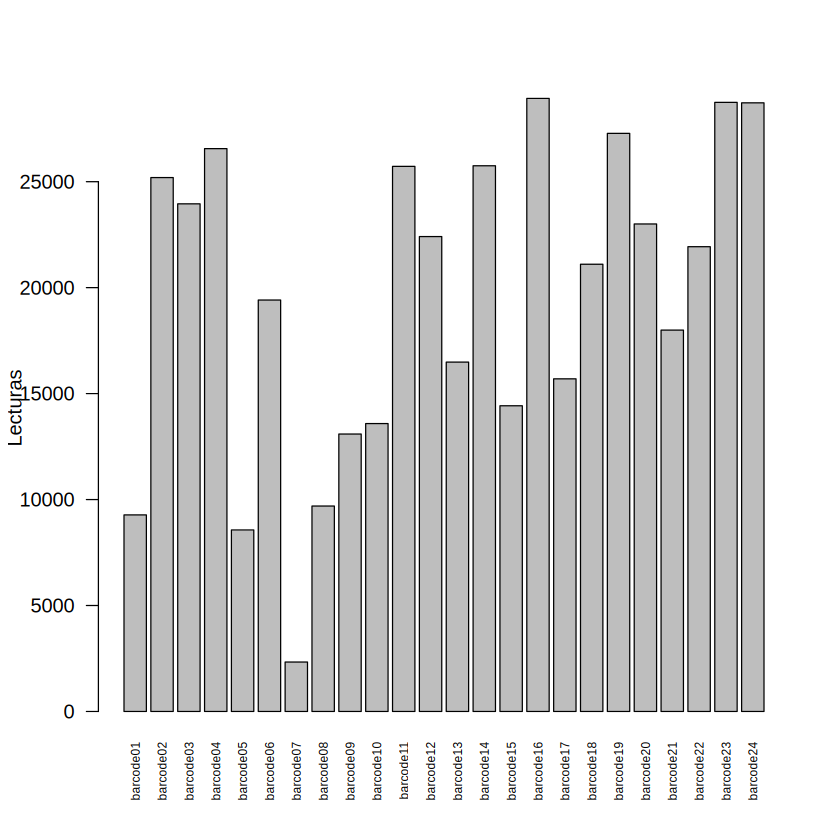

In [ ]:
# Seleccionar solo las columnas de conteos
conteos <- as.matrix(datos[, 2:25])
rownames(conteos) <- datos$phylum
# Revisar lecturas antes de excluir Unknown
colSums(conteos)
barplot(colSums(conteos), las = 2, cex.names = 0.6, ylab = "Lecturas")

### Interpretación de los resultados

Los resultados de nuestra secuenciación muestran diferencias en el número de lecturas entre las 24 muestras, con valores aproximados entre 2.300 y 29.000 lecturas.

El barcode07 presenta la menor profundidad de secuenciación, mientras que los barcodes 16, 23 y 24 presentan los mayores conteos.

Estas diferencias podrían estar asociadas a distintas etapas del procedimiento experimental y afectar la detección de taxones bacterianos poco abundantes.

Por esta razón, para comparar la composición bacteriana entre muestras, transformaremos los conteos en abundancias relativas.

**Preguntas:**

- ¿Qué etapas del práctico de laboratorio podrían explicar las diferencias observadas?
- ¿Una muestra con más lecturas contiene necesariamente más bacterias?
- ¿Deberíamos eliminar el barcode07 del análisis? ¿Qué información adicional necesitaríamos para tomar esta decisión?

In [ ]:
# Excluir categorías sin clasificación y taxones sin lecturas
conteos <- conteos[!is.na(datos$phylum) & !datos$phylum %in% c("Unknown", "", "Total"), ]
conteos <- conteos[rowSums(conteos) > 0, ]
# Transponer: muestras en filas y taxones en columnas
mat <- t(conteos)
dim(mat)
rowSums(mat)

[1] 24  5

barcode01 barcode02 barcode03 barcode04 barcode05 barcode06 barcode07 barcode08 
     9274     25194     23953     26560      8565     19416      2333      9694 
barcode09 barcode10 barcode11 barcode12 barcode13 barcode14 barcode15 barcode16 
    13092     13585     25720     22410     16485     25748     14425     28930 
barcode17 barcode18 barcode19 barcode20 barcode21 barcode22 barcode23 barcode24 
    15697     21104     27278     23004     17996     21930     28743     28719

In [ ]:
orden <- c("Control", "Antibióticos", "Microplásticos",
           "Microplásticos + Antibióticos")
grupo <- factor(rep(orden, each = 6), levels = orden)
metadata <- data.frame(Muestra = rownames(mat), Grupo = grupo)
metadata
# Convertir conteos a porcentajes
rel <- mat / rowSums(mat) * 100
head(rel)

Muestra,Grupo
<chr>,<fct>
barcode01,Control
barcode02,Control
barcode03,Control
barcode04,Control
barcode05,Control
barcode06,Control
barcode07,Antibióticos
barcode08,Antibióticos
barcode09,Antibióticos


,Actinomycetota,Bacillota,Bacteroidota,Deferribacterota,Verrucomicrobiota
barcode01,0.9381065,94.38214,4.679750,0.00000000,0.00000000
barcode02,0.7620862,95.47511,3.719139,0.04366119,0.00000000
barcode03,0.5385547,92.86519,6.283138,0.05844779,0.25466539
barcode04,0.4442771,95.08283,4.393825,0.00000000,0.07906627
barcode05,0.5253940,92.57443,6.900175,0.00000000,0.00000000
barcode06,0.6334981,95.95694,3.234446,0.17511331,0.00000000


### Composición de filos
La abundancia relativa expresa el porcentaje de lecturas asignadas a cada taxón dentro de cada muestra.

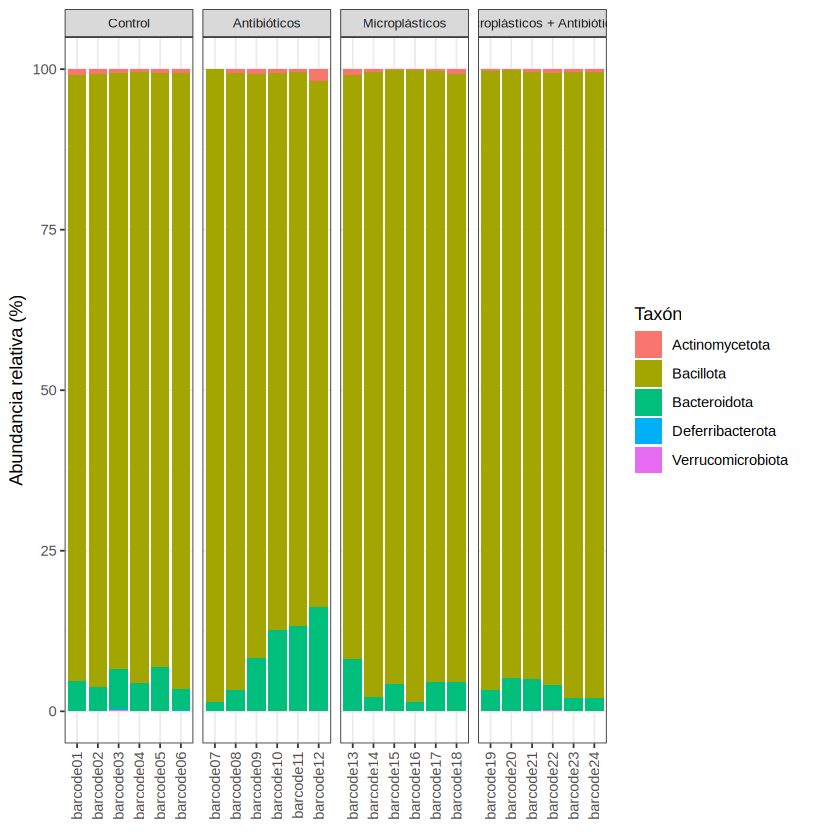

In [ ]:
top <- colnames(rel)
rel_top <- rel[, top, drop = FALSE]
# Mostrar las muestras agrupadas en el orden experimental
composicion <- as.data.frame(as.table(rel_top))
colnames(composicion) <- c("Muestra", "Taxon", "Abundancia")
composicion$Grupo <- grupo[match(composicion$Muestra, metadata$Muestra)]

ggplot(composicion, aes(Muestra, Abundancia, fill = Taxon)) +
  geom_col() +
  facet_grid(. ~ Grupo, scales = "free_x", space = "free_x") +
  labs(x = NULL, y = "Abundancia relativa (%)", fill = "Taxón") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
        strip.text = element_text(size = 8))

**Discusión:** ¿Qué taxones predominan? ¿Por qué excluir Unknown?

## Importar tabla de familias
Cada fila representa una categoría taxonómica; las columnas barcode contienen conteos de lecturas.

In [ ]:
datos <- read.csv("wf-16s-counts-family.csv")
head(datos)
dim(datos)

,family,barcode01,barcode02,barcode03,barcode04,barcode05,barcode06,barcode07,barcode08,barcode09,⋯,barcode22,barcode23,barcode24,total,superkingdom,kingdom,phylum,class,order,tax
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Corynebacteriaceae,0,0,0,0,0,0,0,0,0,⋯,16,0,0,16,Bacteria,Bacillati,Actinomycetota,Actinomycetes,Mycobacteriales,Bacteria;Bacillati;Actinomycetota;Actinomycetes;Mycobacteriales;Corynebacteriaceae
2,Eggerthellaceae,87,192,129,118,45,123,0,56,96,⋯,100,130,120,2509,Bacteria,Bacillati,Actinomycetota,Coriobacteriia,Eggerthellales,Bacteria;Bacillati;Actinomycetota;Coriobacteriia;Eggerthellales;Eggerthellaceae
3,Paenibacillaceae,0,0,0,0,0,0,0,0,0,⋯,60,0,11,113,Bacteria,Bacillati,Bacillota,Bacilli,Bacillales,Bacteria;Bacillati;Bacillota;Bacilli;Bacillales;Paenibacillaceae
4,Staphylococcaceae,0,537,82,196,0,0,0,0,0,⋯,86,94,279,1691,Bacteria,Bacillati,Bacillota,Bacilli,Bacillales,Bacteria;Bacillati;Bacillota;Bacilli;Bacillales;Staphylococcaceae
5,Enterococcaceae,0,0,0,0,0,0,0,0,0,⋯,0,0,0,37,Bacteria,Bacillati,Bacillota,Bacilli,Lactobacillales,Bacteria;Bacillati;Bacillota;Bacilli;Lactobacillales;Enterococcaceae
6,Lactobacillaceae,2407,14101,5985,16328,4336,7738,2091,8366,8719,⋯,15691,24270,25601,289488,Bacteria,Bacillati,Bacillota,Bacilli,Lactobacillales,Bacteria;Bacillati;Bacillota;Bacilli;Lactobacillales;Lactobacillaceae


[1] 37 32

barcode01 barcode02 barcode03 barcode04 barcode05 barcode06 barcode07 barcode08 
     9275     25194     23954     26560      8566     19416      2333      9694 
barcode09 barcode10 barcode11 barcode12 barcode13 barcode14 barcode15 barcode16 
    13092     13585     25722     22411     16486     25751     14425     28930 
barcode17 barcode18 barcode19 barcode20 barcode21 barcode22 barcode23 barcode24 
    15697     21105     27279     23005     17996     21931     28743     28720

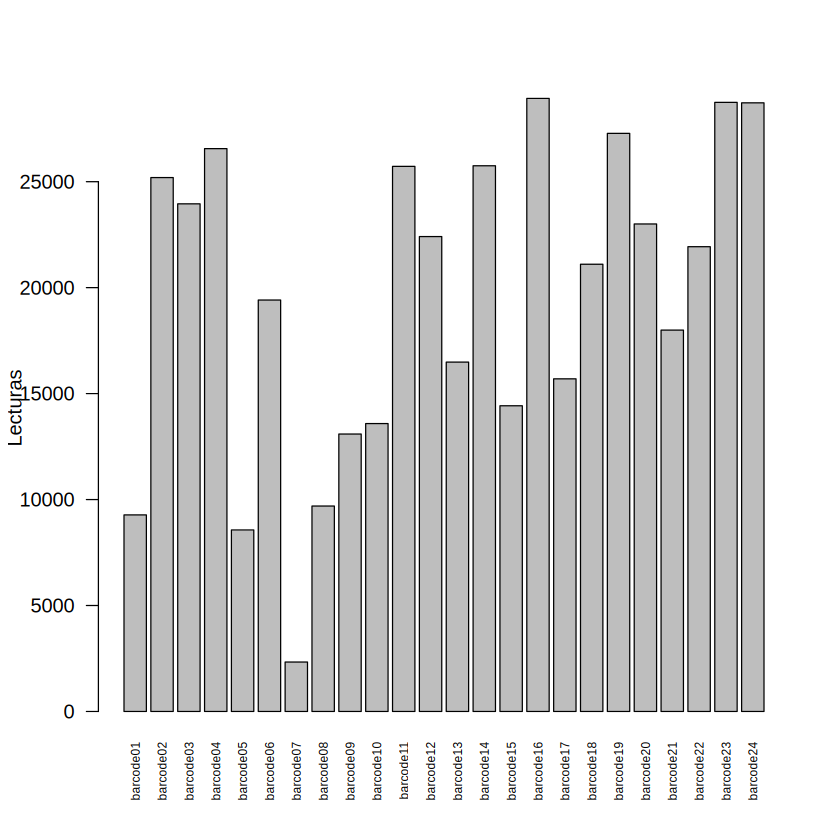

In [ ]:
# Seleccionar solo las columnas de conteos
conteos <- as.matrix(datos[, 2:25])
rownames(conteos) <- datos$family
# Revisar lecturas antes de excluir Unknown
colSums(conteos)
barplot(colSums(conteos), las = 2, cex.names = 0.6, ylab = "Lecturas")

In [ ]:
# Excluir categorías sin clasificación y taxones sin lecturas
conteos <- conteos[!is.na(datos$family) & !datos$family %in% c("Unknown", "", "Total"), ]
conteos <- conteos[rowSums(conteos) > 0, ]
# Transponer: muestras en filas y taxones en columnas
mat <- t(conteos)
dim(mat)
rowSums(mat)

[1] 24 36

barcode01 barcode02 barcode03 barcode04 barcode05 barcode06 barcode07 barcode08 
     9274     25194     23953     26560      8565     19416      2333      9694 
barcode09 barcode10 barcode11 barcode12 barcode13 barcode14 barcode15 barcode16 
    13092     13585     25720     22410     16485     25748     14425     28930 
barcode17 barcode18 barcode19 barcode20 barcode21 barcode22 barcode23 barcode24 
    15697     21104     27278     23004     17996     21930     28743     28719

In [ ]:
orden <- c("Control", "Antibióticos", "Microplásticos",
           "Microplásticos + Antibióticos")
grupo <- factor(rep(orden, each = 6), levels = orden)
metadata <- data.frame(Muestra = rownames(mat), Grupo = grupo)
metadata
# Convertir conteos a porcentajes
rel <- mat / rowSums(mat) * 100
head(rel)

Muestra,Grupo
<chr>,<fct>
barcode01,Control
barcode02,Control
barcode03,Control
barcode04,Control
barcode05,Control
barcode06,Control
barcode07,Antibióticos
barcode08,Antibióticos
barcode09,Antibióticos


,Corynebacteriaceae,Eggerthellaceae,Paenibacillaceae,Staphylococcaceae,Enterococcaceae,Lactobacillaceae,Xylanivirgaceae,Christensenellaceae,Acutalibacteraceae,Butyricicoccaceae,⋯,Peptoniphilaceae,Tissierellaceae,Bacteroidaceae,Muribaculaceae,Paludibacteraceae,Prevotellaceae,Rikenellaceae,Tannerellaceae,Mucispirillaceae,Akkermansiaceae
barcode01,0,0.9381065,0,0.0000000,0,25.95428,0,0,1.6282079,0.00000000,⋯,0.15095967,0,0,4.021997,0.00000000,0,0.6577529,0.00000000,0.00000000,0.00000000
barcode02,0,0.7620862,0,2.1314599,0,55.96968,0,0,0.6231642,0.00000000,⋯,0.05556879,0,0,2.925300,0.04366119,0,0.7501786,0.00000000,0.04366119,0.00000000
barcode03,0,0.5385547,0,0.3423371,0,24.98643,0,0,0.3840855,0.05844779,⋯,0.08349685,0,0,5.581764,0.06262264,0,0.5636037,0.07514716,0.05844779,0.25466539
barcode04,0,0.4442771,0,0.7379518,0,61.47590,0,0,1.5097892,0.00000000,⋯,0.06024096,0,0,3.305723,0.00000000,0,1.0881024,0.00000000,0.00000000,0.07906627
barcode05,0,0.5253940,0,0.0000000,0,50.62464,0,0,0.8523059,0.00000000,⋯,0.00000000,0,0,5.300642,0.00000000,0,1.5995330,0.00000000,0.00000000,0.00000000
barcode06,0,0.6334981,0,0.0000000,0,39.85373,0,0,0.8343634,0.19056448,⋯,0.00000000,0,0,3.234446,0.00000000,0,0.0000000,0.00000000,0.17511331,0.00000000


### Composición de familias
La abundancia relativa expresa el porcentaje de lecturas asignadas a cada taxón dentro de cada muestra.

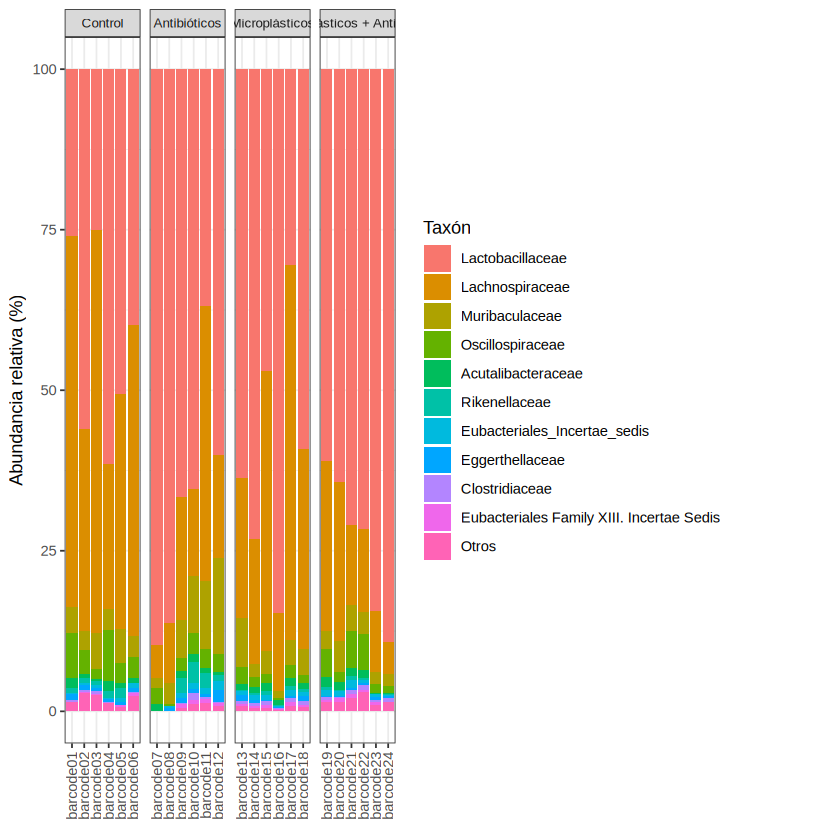

In [ ]:
top <- names(sort(colMeans(rel), decreasing = TRUE))[1:10]
rel_top <- rel[, top, drop = FALSE]
rel_top <- cbind(rel_top, Otros = pmax(0, 100 - rowSums(rel_top)))
# Mostrar las muestras agrupadas en el orden experimental
composicion <- as.data.frame(as.table(rel_top))
colnames(composicion) <- c("Muestra", "Taxon", "Abundancia")
composicion$Grupo <- grupo[match(composicion$Muestra, metadata$Muestra)]

ggplot(composicion, aes(Muestra, Abundancia, fill = Taxon)) +
  geom_col() +
  facet_grid(. ~ Grupo, scales = "free_x", space = "free_x") +
  labs(x = NULL, y = "Abundancia relativa (%)", fill = "Taxón") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
        strip.text = element_text(size = 8))

**Discusión:** ¿Qué taxones predominan? ¿Por qué excluir Unknown?

## Diversidad alfa
La riqueza cuenta taxones detectados; Shannon considera también su distribución. Se calcula a la resolución taxonómica disponible, no a nivel de ASV.

In [ ]:
alpha <- data.frame(Grupo = grupo, Riqueza = specnumber(mat),
                    Shannon = diversity(mat, index = "shannon"))
head(alpha)

,Grupo,Riqueza,Shannon
,<fct>,<int>,<dbl>
barcode01,Control,12,1.232018
barcode02,Control,16,1.193234
barcode03,Control,21,1.140071
barcode04,Control,14,1.178485
barcode05,Control,11,1.190666
barcode06,Control,14,1.201907


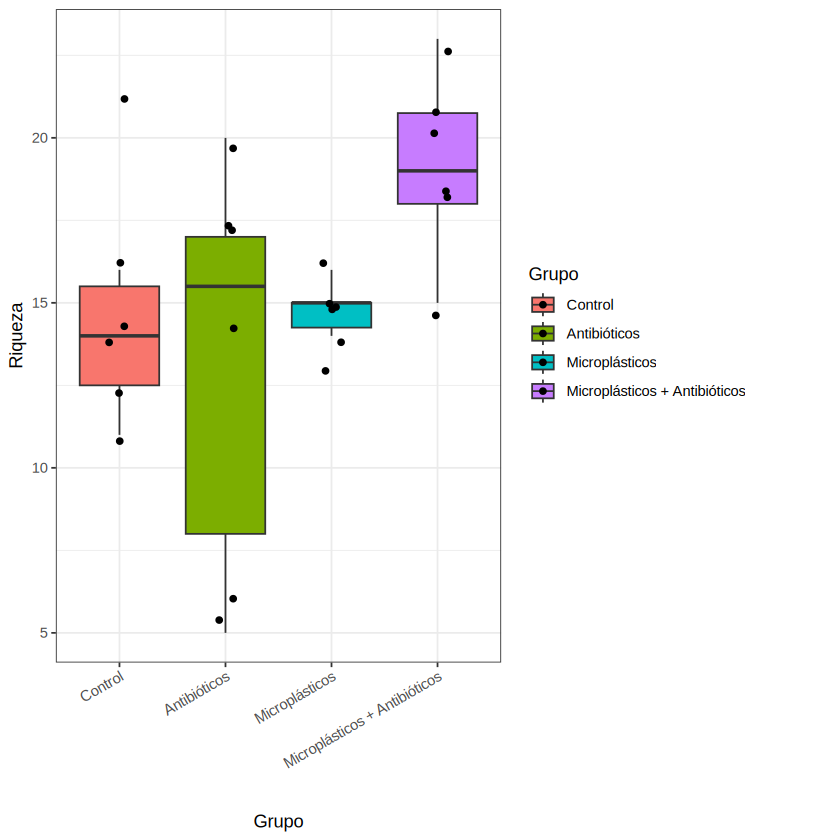

In [ ]:
ggplot(alpha, aes(Grupo, Riqueza, fill = Grupo)) +
  geom_boxplot(outlier.shape = NA) + geom_jitter(width = 0.1) + theme_bw() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

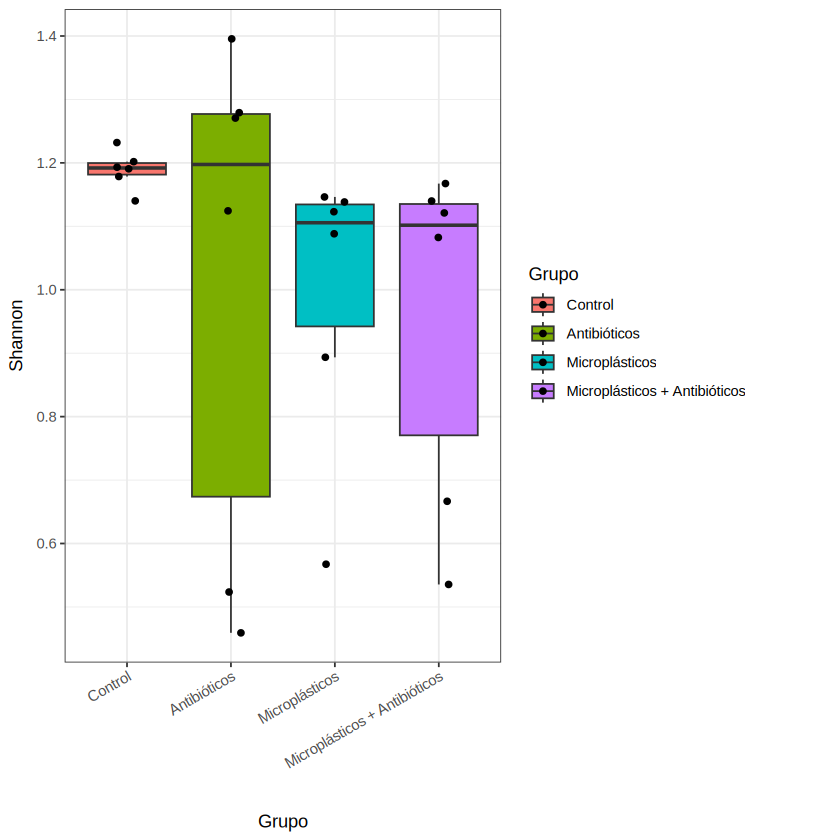

In [ ]:
ggplot(alpha, aes(Grupo, Shannon, fill = Grupo)) +
  geom_boxplot(outlier.shape = NA) + geom_jitter(width = 0.1) + theme_bw() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

### Comparación estadística de la diversidad alfa
Kruskal–Wallis evalúa si existen diferencias entre los cuatro grupos. Si p < 0,05, exploramos qué pares difieren mediante Wilcoxon con ajuste de Holm.

In [ ]:
kruskal.test(Riqueza ~ Grupo, data = alpha)
kruskal.test(Shannon ~ Grupo, data = alpha)


	Kruskal-Wallis rank sum test

data:  Riqueza by Grupo
Kruskal-Wallis chi-squared = 7.4122, df = 3, p-value = 0.05986



	Kruskal-Wallis rank sum test

data:  Shannon by Grupo
Kruskal-Wallis chi-squared = 7.0133, df = 3, p-value = 0.07147


In [ ]:
# Ejecutar para cada índice cuya prueba global sea significativa
pairwise.wilcox.test(alpha$Riqueza, alpha$Grupo, p.adjust.method = "holm", exact = FALSE)
pairwise.wilcox.test(alpha$Shannon, alpha$Grupo, p.adjust.method = "holm", exact = FALSE)


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  alpha$Riqueza and alpha$Grupo 

                              Control Antibióticos Microplásticos
Antibióticos                  1.000   -            -             
Microplásticos                1.000   1.000        -             
Microplásticos + Antibióticos 0.267   0.267        0.086         

P value adjustment method: holm 


	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  alpha$Shannon and alpha$Grupo 

                              Control Antibióticos Microplásticos
Antibióticos                  1.000   -            -             
Microplásticos                0.049   1.000        -             
Microplásticos + Antibióticos 0.049   1.000        1.000         

P value adjustment method: holm 

**Discusión:** ¿Qué índice presenta diferencias? ¿Qué comparaciones siguen siendo significativas después del ajuste?

**Discusión:** ¿Coinciden la riqueza y Shannon? ¿Un gráfico demuestra significancia?

## Diversidad beta
Bray–Curtis compara perfiles de abundancia y PCoA representa sus distancias. Las elipses del 95 % describen la distribución de las muestras por grupo; no constituyen una prueba de diferencias significativas. Si un grupo tiene muy pocos puntos distintos o una covarianza singular, su elipse puede no calcularse.

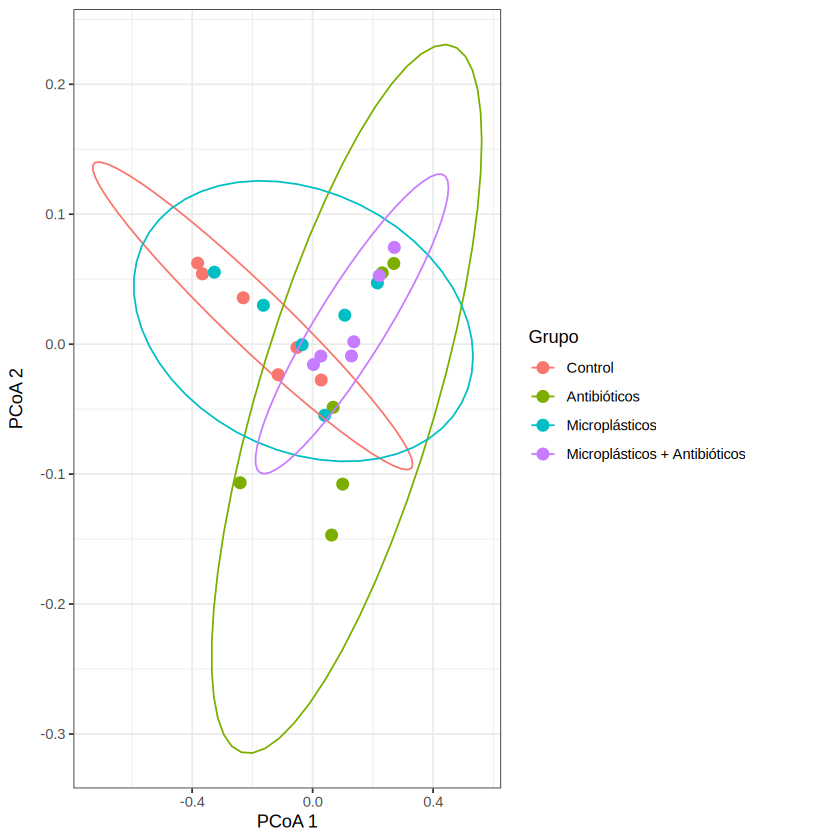

In [ ]:
distancia <- vegdist(rel, method = "bray")
pcoa <- cmdscale(distancia, k = 2, eig = TRUE)
coord <- data.frame(PC1 = pcoa$points[,1], PC2 = pcoa$points[,2], Grupo = grupo)
ggplot(coord, aes(PC1, PC2, color = Grupo)) +
  geom_point(size = 3) +
  stat_ellipse(level = 0.95, type = "t") +
  labs(x = "PCoA 1", y = "PCoA 2") +
  theme_bw()

### Comparación estadística de la diversidad beta
PERMANOVA evalúa diferencias en la composición global. BETADISPER evalúa diferencias de dispersión entre grupos. Interpretar ambas pruebas conjuntamente.

In [ ]:
set.seed(123)
adonis2(distancia ~ Grupo, data = metadata, permutations = 999)

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Model,3,0.3951259,0.381384,4.110077,0.013
Residual,20,0.6409059,0.618616,NA,NA
Total,23,1.0360318,1.000000,NA,NA


In [ ]:
dispersion <- betadisper(distancia, grupo)
set.seed(123)
permutest(dispersion, permutations = 999)

Warning message in betadisper(distancia, grupo):
“some squared distances are negative and changed to zero”



Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)
Groups     3 0.013791 0.0045971 0.5206    999   0.66
Residuals 20 0.176605 0.0088303                     

**Discusión:** ¿Qué indican R² y el valor p de PERMANOVA? Si BETADISPER es significativo, ¿por qué debemos interpretar PERMANOVA con cautela?

## Exploración de diferencias de abundancia relativa de familias
Compararemos las familias presentes en al menos seis muestras para reducir la influencia de taxones muy poco frecuentes. Usaremos Kruskal–Wallis y ajustaremos los valores p mediante Benjamini–Hochberg (FDR). Este análisis es exploratorio: no controla formalmente la composicionalidad ni estima abundancia absoluta.

In [ ]:
# Seleccionar familias presentes en al menos seis muestras
familias <- rel[, colSums(rel > 0) >= 6, drop = FALSE]
dim(familias)

[1] 24 19

In [ ]:
# Una prueba de Kruskal–Wallis por familia
p <- apply(familias, 2, function(x) kruskal.test(x ~ grupo)$p.value)
resultados <- data.frame(Familia = names(p), p = as.numeric(p))
resultados$FDR <- p.adjust(resultados$p, method = "BH")
resultados <- resultados[order(resultados$FDR, resultados$p), ]
resultados

,Familia,p,FDR
,<chr>,<dbl>,<dbl>
7,Eubacteriaceae,0.0003673843,0.006980301
11,Anaerotignaceae,0.0007722126,0.007336020
2,Staphylococcaceae,0.0017297217,0.010954904
12,Lachnospiraceae,0.0158379496,0.075230261
3,Lactobacillaceae,0.0313058139,0.118962093
6,Clostridiaceae,0.0681985792,0.215962167
10,Oscillospiraceae,0.0934169132,0.253560193
5,Butyricicoccaceae,0.1615494335,0.347101164
18,Tannerellaceae,0.1668420629,0.347101164


In [ ]:
# Familias con FDR menor que 0,05
subset(resultados, FDR < 0.05)

,Familia,p,FDR
,<chr>,<dbl>,<dbl>
7,Eubacteriaceae,0.0003673843,0.006980301
11,Anaerotignaceae,0.0007722126,0.007336020
2,Staphylococcaceae,0.0017297217,0.010954904


### Visualización de tres familias
Para practicar, graficaremos las tres familias con menor FDR (o menos si no hay tres disponibles). Aparecer aquí no significa que sean significativas: revisar la tabla anterior.

In [ ]:
seleccion <- head(resultados$Familia, 3)
comparacion <- as.data.frame(as.table(rel[, seleccion, drop = FALSE]))
colnames(comparacion) <- c("Muestra", "Familia", "Abundancia")
comparacion$Grupo <- grupo[match(comparacion$Muestra, metadata$Muestra)]

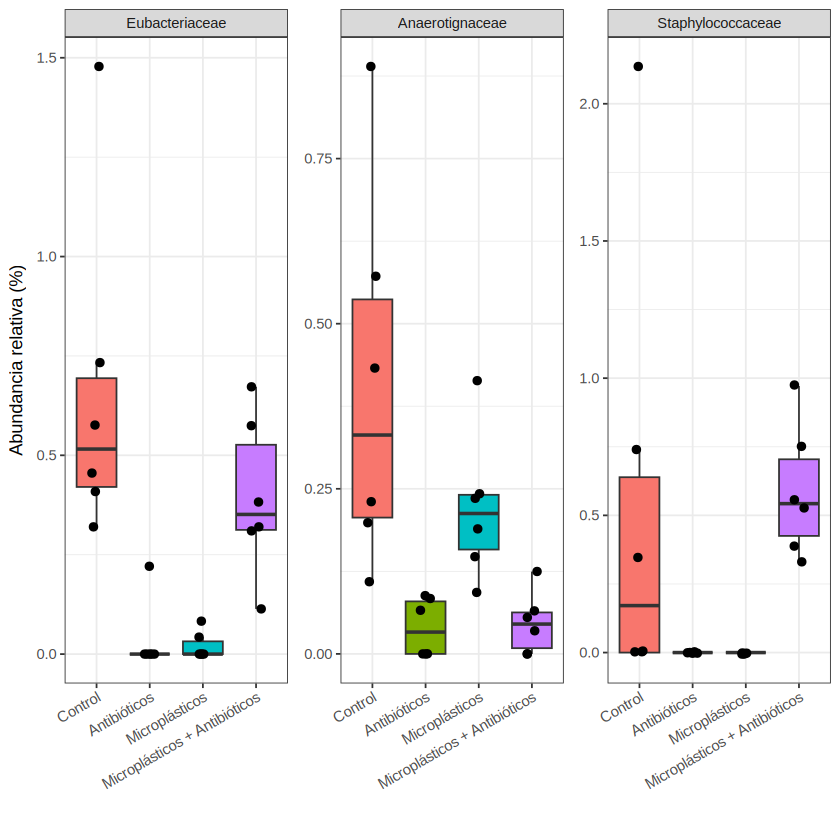

In [ ]:
ggplot(comparacion, aes(Grupo, Abundancia, fill = Grupo)) +
  geom_boxplot(outlier.shape = NA) +
  geom_jitter(width = 0.1, size = 2) +
  facet_wrap(~ Familia, scales = "free_y") +
  labs(x = NULL, y = "Abundancia relativa (%)") +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1),
        legend.position = "none")

**Discusión:** ¿Qué familias presentan FDR < 0,05? ¿En qué grupos parecen más abundantes? Una prueba global significativa no identifica por sí sola los pares de grupos diferentes. Si ninguna familia es significativa, reportar ese resultado.

## Cierre
En la tarea aplicaremos el flujo a géneros bacterianos e interpretaremos los resultados de forma autónoma.

**Limitaciones:** la riqueza observada depende de la profundidad de secuenciación. Los porcentajes se calculan sobre lecturas clasificadas en el nivel analizado y no equivalen a cantidades absolutas de bacterias. Las comparaciones entre grupos son un ejercicio docente mientras no se confirmen los metadatos.